## Credit Stress Index Analysis V3

In [1]:
import os
import datetime as dt

from dotenv import load_dotenv
from pathlib import Path

import json
import time
from urllib.parse import urljoin, urlencode
import requests

import numpy as np
import pandas as pd

import plotly
import plotly.graph_objs as go
import plotly.express as px
import seaborn as sns
import matplotlib.pyplot as plt

from Modules.utility import Utility
from Modules.show_plot import ShowPlot
from Modules.reques_api import RequestApi
from Modules.get_market_data import GetMarketData
from Modules.stock_prices_and_market_data import ClassStockPricesMarketData
from Modules.financial import Financial
from Modules.pdf_url_to_markdown import PDFUrlToMarkdown
from Modules.webpage_to_markdown import WebpageToMarkdown
from Modules.compute_fibonacci_extension import ComputeFibonacciExtension

In [2]:
# FRED API key for accessing Federal Reserve Economic Data
FRED_API_KEY = os.getenv("FRED_API_KEY")
# Output directory for storing downloaded data
API_BASE_URL = os.getenv("API_BASE_URL", "http://localhost:8000")
request_api = RequestApi(API_BASE_URL)
get_market_data = GetMarketData(Path('/workspace/data'))
utility = Utility()
stock_prices_market_data = ClassStockPricesMarketData()
financial = Financial()
# URLからPDFをダウンロードしてMarkdownに変換するクラスのインスタンスを作成
pdf_to_md = PDFUrlToMarkdown()
# WEBページをMarkdownに変換する関数
webpage_to_markdown = WebpageToMarkdown()
# Fibonacciエクステンションを計算するクラスのインスタンスを作成
fibonacci_extension = ComputeFibonacciExtension()

In [3]:
# Date range for fetching API s
start = '2007-01-01'
end = dt.datetime.now().strftime('%Y-%m-%d')
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)

#### SJBの時系列データを取得

In [4]:
sjb = 'SJB'

response = request_api.update_stock_timeseries_data(
    code=sjb,
    market=None,
    start=start,
    end=end
)
response

{'result': True}

In [5]:
sjb_df = request_api.get_stock_time_series_data(
    code=sjb,
    market=None,
    start=start,
    end=end
)
sjb_df["date"] = pd.to_datetime(sjb_df["date"])
sjb_df

取得件数: 3912


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
0,1165760,SJB,None,2011-03-22,33.406315,33.531590,33.406315,33.531590,7700,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
1,1165761,SJB,None,2011-03-23,33.406315,33.539940,33.406315,33.539940,5900,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,1165762,SJB,None,2011-03-24,33.347858,33.431373,33.347858,33.431373,1700,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,1165763,SJB,None,2011-03-25,33.381256,33.397960,33.364553,33.397960,3600,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,1165764,SJB,None,2011-03-28,33.347858,33.423023,33.339505,33.423023,99800,33.464777,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3907,1169667,SJB,None,2026-10-05,15.480000,15.520000,15.480000,15.510000,128500,15.470000,...,15.075001,61.081704,True,NaN,NaN,NaN,NaN,NaN,NaN,False
3908,1169668,SJB,None,2026-10-06,15.420000,15.450000,15.410000,15.430000,235700,15.470000,...,15.090617,65.837104,True,NaN,NaN,NaN,NaN,NaN,93.196581,False
3909,1169669,SJB,None,2026-10-07,15.450000,15.490000,15.430000,15.440000,85700,15.468000,...,15.105892,70.472979,True,NaN,NaN,NaN,NaN,NaN,NaN,False
3910,1169670,SJB,None,2026-10-08,15.450000,15.490000,15.450000,15.450000,358900,15.456000,...,15.120783,74.494152,True,NaN,NaN,NaN,NaN,NaN,NaN,False


#### DX-Yの時系列データを取得

In [6]:
dxy = 'DX-Y'
market = 'NYB'

response = request_api.update_stock_timeseries_data(
    code=dxy,
    market=market,
    start=start,
    end=end
)
response

{'result': True}

In [7]:
dx_df = request_api.get_stock_time_series_data(
    code=dxy,
    market=market,
    start=start,
    end=end
)
dx_df["date"] = pd.to_datetime(dx_df["date"])
dx_df

取得件数: 5185


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
0,1091754,DX-Y,NYB,2006-03-07,90.769997,90.860001,89.860001,89.910004,0,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
1,1091755,DX-Y,NYB,2006-03-08,90.620003,90.800003,90.430000,90.709999,0,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,1091756,DX-Y,NYB,2006-03-09,90.750000,90.790001,90.379997,90.599998,0,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,1091757,DX-Y,NYB,2006-03-10,90.849998,91.160004,90.589996,90.779999,0,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,1091758,DX-Y,NYB,2006-03-13,90.540001,90.870003,90.519997,90.830002,0,90.566000,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5180,1187717,DX-Y,NYB,2026-10-05,102.169998,102.540001,101.860001,101.919998,0,101.602000,...,99.174593,8.025271,True,NaN,NaN,NaN,NaN,NaN,NaN,False
5181,1187718,DX-Y,NYB,2026-10-06,101.830002,102.290001,101.750000,102.139999,0,101.792000,...,99.206891,16.750619,True,NaN,NaN,NaN,NaN,NaN,NaN,False
5182,1187719,DX-Y,NYB,2026-10-07,102.239998,102.500000,101.889999,101.889999,0,101.887999,...,99.275607,26.278494,True,NaN,NaN,NaN,NaN,NaN,91.82906,False
5183,1187720,DX-Y,NYB,2026-10-08,102.139999,102.470001,102.029999,102.230003,0,102.039999,...,99.330177,35.055067,True,NaN,NaN,NaN,NaN,NaN,NaN,False


#### HYGの時系列データを取得

In [8]:
hyg = 'HYG'

response = request_api.update_stock_timeseries_data(
    code=hyg,
    market=None,
    start=start,
    end=end
)
response

{'result': True}

In [9]:
hyg_df = request_api.get_stock_time_series_data(
    code=hyg,
    market=None,
    start=start,
    end=end
)
hyg_df["date"] = pd.to_datetime(hyg_df["date"])
hyg_df

取得件数: 4907


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
0,1169672,HYG,None,2007-04-11,31.084785,31.096701,31.084785,31.084785,1900,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
1,1169673,HYG,None,2007-04-12,31.105623,31.105623,31.084771,31.105623,6100,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,1169674,HYG,None,2007-04-13,31.049049,31.126499,31.049049,31.096711,3400,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,1169675,HYG,None,2007-04-16,31.037115,31.060945,31.025199,31.060945,7600,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,1169676,HYG,None,2007-04-17,31.022232,31.099684,31.022232,31.025212,28100,31.074655,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4902,1174574,HYG,None,2026-10-05,76.980003,77.019997,76.809998,76.889999,39142800,77.050616,...,77.430472,-36.032613,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4903,1174575,HYG,None,2026-10-06,77.269997,77.320000,77.139999,77.150002,47352500,77.027371,...,77.356343,-44.040809,False,NaN,NaN,NaN,NaN,NaN,NaN,True
4904,1174576,HYG,None,2026-10-07,77.180000,77.209999,76.930000,77.000000,59309100,77.002000,...,77.275755,-51.707504,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4905,1174577,HYG,None,2026-10-08,77.139999,77.180000,76.980003,77.070000,44872800,77.066000,...,77.207912,-58.375309,False,NaN,NaN,NaN,NaN,NaN,NaN,True


#### TLTの時系列データを取得

In [10]:
tlt = 'TLT'

response = request_api.update_stock_timeseries_data(
    code=tlt,
    market=None,
    start=start,
    end=end
)
response

{'result': True}

In [11]:
tlt_df = request_api.get_stock_time_series_data(
    code=tlt,
    market=None,
    start=start,
    end=end
)
tlt_df["date"] = pd.to_datetime(tlt_df["date"])
tlt_df

取得件数: 5182


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
0,1175486,TLT,None,2006-03-07,45.815853,45.888240,45.660736,45.707273,1692900,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
1,1175487,TLT,None,2006-03-08,45.800343,45.955455,45.733123,45.795171,1184700,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,1175488,TLT,None,2006-03-09,45.815853,45.846875,45.640054,45.789999,282100,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,1175489,TLT,None,2006-03-10,45.645233,45.743474,45.505631,45.665916,1086900,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,1175490,TLT,None,2006-03-13,45.609039,45.640061,45.505631,45.572846,1740100,45.706241,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5177,1180663,TLT,None,2026-10-05,77.110001,77.260002,76.690002,77.160004,49106700,77.618303,...,78.701412,-72.457953,False,NaN,NaN,NaN,NaN,NaN,NaN,False
5178,1180664,TLT,None,2026-10-06,77.279999,77.580002,77.070000,77.169998,31085900,77.411296,...,78.433292,-74.293520,False,NaN,NaN,NaN,NaN,-85.0,NaN,False
5179,1180665,TLT,None,2026-10-07,77.150002,77.320000,76.430000,76.459999,40200000,77.134001,...,78.110772,-75.147272,False,NaN,NaN,NaN,NaN,NaN,NaN,False
5180,1180666,TLT,None,2026-10-08,77.870003,77.910004,77.070000,77.190002,49484200,77.184001,...,77.891491,-75.078972,False,NaN,NaN,NaN,NaN,NaN,NaN,True


#### FREDの月次データを取得

In [12]:
fred_url = "https://api.stlouisfed.org/fred/series/observations"
series_mapping = {
    "DFF": "effective_federal_funds_rate",  # 実効FF金利
    "DFII10": "real_10y",                   # 10年TIPS実質金利
    "FEDFUNDS": "ff_rate",                  # FF金利
    "DFEDTARU": "maximum_interest_rate",    # 上限金利
    "DFEDTARL": "minimum_interest_rate",    # 下限金利
    "DGS2": "us_treasury_2y",               # 2年米国債
    "DGS5": "us_treasury_5y",               # 5年米国債
    "DGS10": "us_treasury_10y",             # 10年米国債
    "DGS30": "us_treasury_30y",             # 30年米国債
    "M1SL": "m1_money_stock",               # M1マネーストック
    "M2SL": "m2_money_stock",               # M2マネーストック
}
observation_start = "2007-01-01"
observation_end = end
base_fred_params = {
    "api_key": FRED_API_KEY,
    "file_type": "json",
    "observation_start": observation_start,
    "observation_end": observation_end,
    "frequency": "m",
    "aggregation_method": "avg",
}
fred_dfs = []
for series_id, series_name in series_mapping.items():
    fred_params = base_fred_params.copy()
    fred_params["series_id"] = series_id
    fred_res = requests.get(fred_url, params=fred_params)
    fred_df = pd.DataFrame(fred_res.json()["observations"]).assign(**{
        "date": lambda df: pd.to_datetime(df["date"]),
        "value": lambda df: pd.to_numeric(df["value"], errors="coerce"),
        "interest_rate_type": series_name,
    })
    fred_dfs.append(fred_df)
    time.sleep(5)
    
us_treasury_df = pd.concat(fred_dfs)
us_treasury_df

,realtime_start,realtime_end,date,value,interest_rate_type
0,2026-10-10,2026-10-10,2007-01-01,5.25,effective_federal_funds_rate
1,2026-10-10,2026-10-10,2007-02-01,5.26,effective_federal_funds_rate
2,2026-10-10,2026-10-10,2007-03-01,5.26,effective_federal_funds_rate
3,2026-10-10,2026-10-10,2007-04-01,5.25,effective_federal_funds_rate
4,2026-10-10,2026-10-10,2007-05-01,5.25,effective_federal_funds_rate
...,...,...,...,...,...
231,2026-10-10,2026-10-10,2026-04-01,22756.60,m2_money_stock
232,2026-10-10,2026-10-10,2026-05-01,23013.70,m2_money_stock
233,2026-10-10,2026-10-10,2026-06-01,23114.90,m2_money_stock
234,2026-10-10,2026-10-10,2026-07-01,23217.90,m2_money_stock


### CSI v2 (Credit Stress Index v3)

#### 0. ETF月次データ準備
- HYG
- SJB
- TLT
- DXY
を分析可能な形へ統一

In [13]:
etf_dict = {
    "hyg": hyg_df,
    "sjb": sjb_df,
    "tlt": tlt_df,
    "dxy": dx_df,
}

for k, df in etf_dict.items():
    df["date"] = pd.to_datetime(df["date"])
    df.sort_values("date", inplace=True)

display(
    {
        k: len(v)
        for k, v in etf_dict.items()
    }
)

{'hyg': 4907, 'sjb': 3912, 'tlt': 5182, 'dxy': 5185}

**実装内容**

- `etf_dict` に4銘柄(`hyg`, `sjb`, `tlt`, `dxy`)の日次 DataFrame を辞書としてまとめる。
- 各 DataFrame の `date` 列を `datetime` 型へ変換し、`sort_values("date", inplace=True)` で昇順に並べ替える(`inplace=True` のため元の `hyg_df` などにも反映される)。
- `display` で各銘柄の行数を確認し、取得期間にずれがないかを点検する。

後続の `resample` や `shift`、`rolling` は時間順が前提のため、ここで日付昇順に揃えている。

#### 1. ETFデータ月次化

In [14]:
monthly_etfs = []

for name, df in etf_dict.items():

    monthly = (
        df
        .set_index("date")
        .resample("ME")
        .last()[["close"]]
        .rename(
            columns={
                "close": name
            }
        )
    )

    monthly_etfs.append(
        monthly.reset_index()
    )

etf_monthly = monthly_etfs[0]

for m in monthly_etfs[1:]:

    etf_monthly = (
        etf_monthly
        .merge(
            m,
            on="date",
            how="outer"
        )
    )

display(etf_monthly.tail())

,date,hyg,sjb,tlt,dxy
243,2026-06-30,78.465107,15.009434,85.805249,101.120003
244,2026-07-31,78.296741,15.108637,81.477568,100.019997
245,2026-08-31,78.924394,15.039195,81.825639,99.699997
246,2026-09-30,77.126854,15.450000,77.846475,101.410004
247,2026-10-31,77.209999,15.470000,77.709999,102.129997


**実装内容**

- 銘柄ごとに `date` をインデックスにして `resample("ME").last()` を実行し、各月の最終営業日の終値 $P_m$ を月次値とする。

$$
P_m = P_{t^*},\quad t^* = \max\{\,t \mid t \in \text{月}\ m\,\}
$$

- 列名 `close` を銘柄名(`hyg` など)に変更する。
- 4銘柄を `merge(on="date", how="outer")` で順次結合し、月末日付をキーとした `etf_monthly` を作る。
- `"ME"` は pandas 3.x の月末頻度エイリアスである。

#### 2. FREDデータ統合

In [15]:
fred_df = (
    us_treasury_df
    .pivot(
        index="date",
        columns="interest_rate_type",
        values="value"
    )
    .reset_index()
)

etf_monthly["month"] = (
    pd.to_datetime(etf_monthly["date"])
      .dt.to_period("M")
)

fred_df["month"] = (
    pd.to_datetime(fred_df["date"])
      .dt.to_period("M")
)

model_df = (
    etf_monthly
    .merge(
        fred_df.drop(columns=["date"]),
        on="month",
        how="left"
    )
)

model_df = (
    model_df
    .sort_values("date")
    .ffill()
)

**実装内容**

- `us_treasury_df`(縦持ち)を `pivot` で、行=`date`、列=`interest_rate_type` の横持ち `fred_df` に変換する。
- ETF は月末日、FRED は月初日付なので、日付で直接結合できない。両方に `to_period("M")` で年月列 `month` を作り、これをキーに `merge(how="left")` する。
- 結合後は `date` で並べ替えて `ffill()` を適用し、欠損を直前の値で補完する。

$$
x_m = \begin{cases} x_m & (x_m\ \text{が存在}) \\ x_{m-1} & (x_m\ \text{が欠損}) \end{cases}
$$

最新月に FRED の値がまだ無い場合でも、直近値で埋めて行を残す。

#### 3. 派生ファクター作成

In [16]:
model_df["m1_yoy"] = (
    model_df["m1_money_stock"]
    .pct_change(12)
)

model_df["m2_yoy"] = (
    model_df["m2_money_stock"]
    .pct_change(12)
)

model_df["m2_mom"] = (
    model_df["m2_money_stock"]
    .pct_change(1)
)

model_df["term_spread"] = (
    model_df["us_treasury_10y"]
    - model_df["us_treasury_2y"]
)

model_df["term_spread_inv"] = (
    -model_df["term_spread"]
)

model_df["hyg_tlt_ratio"] = (
    model_df["hyg"]
    / model_df["tlt"]
)

model_df["hyg_sjb_ratio"] = (
    model_df["hyg"]
    / model_df["sjb"]
)

display(model_df.tail())

,date,hyg,sjb,tlt,dxy,month,effective_federal_funds_rate,ff_rate,m1_money_stock,m2_money_stock,...,us_treasury_2y,us_treasury_30y,us_treasury_5y,m1_yoy,m2_yoy,m2_mom,term_spread,term_spread_inv,hyg_tlt_ratio,hyg_sjb_ratio
243,2026-06-30,78.465107,15.009434,85.805249,101.120003,2026-06,3.63,3.63,19793.0,23114.9,...,4.11,4.95,4.21,0.055818,0.053426,0.004397,0.36,-0.36,0.914456,5.227719
244,2026-07-31,78.296741,15.108637,81.477568,100.019997,2026-07,3.63,3.63,19886.5,23217.9,...,4.22,5.10,4.33,0.057556,0.054132,0.004456,0.38,-0.38,0.960961,5.182250
245,2026-08-31,78.924394,15.039195,81.825639,99.699997,2026-08,3.63,3.63,19991.1,23342.8,...,4.22,5.22,4.38,0.061054,0.056589,0.005379,0.46,-0.46,0.964544,5.247914
246,2026-09-30,77.126854,15.450000,77.846475,101.410004,2026-09,3.75,3.75,19991.1,23342.8,...,4.65,5.37,4.80,0.057467,0.052611,0.000000,0.34,-0.34,0.990756,4.992029
247,2026-10-31,77.209999,15.470000,77.709999,102.129997,2026-10,3.75,3.75,19991.1,23342.8,...,4.65,5.37,4.80,0.052983,0.049124,0.000000,0.34,-0.34,0.993566,4.990950


**実装内容**(`model_df` に次の列を追加)

| 列名 | 定義 |
|---|---|
| `m1_yoy` | $\dfrac{M1_t}{M1_{t-12}}-1$ |
| `m2_yoy` | $\dfrac{M2_t}{M2_{t-12}}-1$ |
| `m2_mom` | $\dfrac{M2_t}{M2_{t-1}}-1$ |
| `term_spread` | $y^{10Y}_t - y^{2Y}_t$ |
| `term_spread_inv` | $-(y^{10Y}_t - y^{2Y}_t)$ |
| `hyg_tlt_ratio` | $\mathrm{HYG}_t / \mathrm{TLT}_t$ |
| `hyg_sjb_ratio` | $\mathrm{HYG}_t / \mathrm{SJB}_t$ |

- `pct_change(12)` は月次データなので前年同月比になる。
- `term_spread_inv` は符号を反転しているため、逆イールドが深いほど大きくなり、ストレス方向の指標になる。
- `hyg_tlt_ratio` と `hyg_sjb_ratio` は、ハイイールド債を国債 ETF との相対で見るクレジット確認用の比率である。

#### 4. 欠損値・データ品質確認

In [17]:
quality_check = pd.DataFrame({
    "missing":
        model_df.isna().sum(),
    "missing_pct":
        model_df.isna().mean()
})

display(
    quality_check.sort_values(
        "missing",
        ascending=False
    )
)


,missing,missing_pct
hyg_sjb_ratio,60,0.241935
sjb,60,0.241935
maximum_interest_rate,34,0.137097
minimum_interest_rate,34,0.137097
m2_yoy,22,0.088710
m1_yoy,22,0.088710
hyg_tlt_ratio,13,0.052419
hyg,13,0.052419
m2_mom,11,0.044355
us_treasury_2y,10,0.040323


**実装内容**

- 各列について欠損数 `isna().sum()` と欠損率 `isna().mean()` を DataFrame にまとめる。
- 欠損数の多い順に表示し、補完後もデータが残っていない列を確認する。

$$
\text{missing\_pct}_j = \frac{1}{T}\sum_{t=1}^{T}\mathbf{1}[x_{t,j}=\text{NaN}]
$$

`m1_yoy` や `m2_yoy` は先頭12行が、`future_return` は末尾3行が構造的に欠損する。

#### 5. 将来リターン作成

In [18]:
model_df["future_return"] = (
    model_df["hyg"]
        .shift(-3)
    /
    model_df["hyg"]
    - 1
)

display(
    model_df[
        ["date", "hyg", "future_return"]
    ].tail()
)

,date,hyg,future_return
243,2026-06-30,78.465107,-0.017055
244,2026-07-31,78.296741,-0.013880
245,2026-08-31,78.924394,NaN
246,2026-09-30,77.126854,NaN
247,2026-10-31,77.209999,NaN


**実装内容**

- 予測対象 `future_return` は、HYG の3か月先リターンである。`shift(-3)` で3行先(3か月先)の価格を現在行に持ってくる。

$$
\mathrm{future\_return}_t = \frac{\mathrm{HYG}_{t+3}}{\mathrm{HYG}_t} - 1
$$

- 末尾3行は将来価格が無いため `NaN` になる。
- 確認として `date`, `hyg`, `future_return` の末尾を表示する。

#### 6. 標準化(z-score)

In [19]:
factor_cols = [
    "dxy",
    "ff_rate",
    "real_10y",
    "term_spread_inv",
    "m2_yoy"
]

for col in factor_cols:

    model_df[f"{col}_z"] = (
        model_df[col]
        -
        model_df[col].mean()
    ) / (
        model_df[col].std()
    )

display(
    model_df[
        [f"{c}_z" for c in factor_cols]
    ].tail()
)

,dxy_z,ff_rate_z,real_10y_z,term_spread_inv_z,m2_yoy_z
243,1.043989,1.039239,1.377423,0.707588,-0.193396
244,0.933054,1.039239,1.549140,0.686419,-0.180106
245,0.900783,1.039239,1.599644,0.601745,-0.133908
246,1.073235,1.102354,1.842067,0.728756,-0.208723
247,1.145845,1.102354,1.842067,0.728756,-0.274292


**実装内容**

- 対象ファクターは `dxy`, `ff_rate`, `real_10y`, `term_spread_inv`, `m2_yoy` の5つである。
- 各列を全期間の平均 $\mu$ と標準偏差 $\sigma$ で標準化し、`{col}_z` 列を作る。

$$
z_t = \frac{x_t - \mu}{\sigma},\quad \mu=\frac{1}{T}\sum_{t}x_t,\quad \sigma=\sqrt{\frac{1}{T-1}\sum_t (x_t-\mu)^2}
$$

- `std()` は pandas の既定でサンプル標準偏差($T-1$ で割る)である。
- 平均と標準偏差を全期間で計算しているため、各時点の z-score は将来のデータも含んだ統計量に依存する(ルックアヘッドの可能性がある)。ローリング窓で計算する方式とは異なる。

In [20]:
print(model_df.columns.tolist())
print(model_df.shape)
model_df.tail()

['date', 'hyg', 'sjb', 'tlt', 'dxy', 'month', 'effective_federal_funds_rate', 'ff_rate', 'm1_money_stock', 'm2_money_stock', 'maximum_interest_rate', 'minimum_interest_rate', 'real_10y', 'us_treasury_10y', 'us_treasury_2y', 'us_treasury_30y', 'us_treasury_5y', 'm1_yoy', 'm2_yoy', 'm2_mom', 'term_spread', 'term_spread_inv', 'hyg_tlt_ratio', 'hyg_sjb_ratio', 'future_return', 'dxy_z', 'ff_rate_z', 'real_10y_z', 'term_spread_inv_z', 'm2_yoy_z']
(248, 30)


,date,hyg,sjb,tlt,dxy,month,effective_federal_funds_rate,ff_rate,m1_money_stock,m2_money_stock,...,term_spread,term_spread_inv,hyg_tlt_ratio,hyg_sjb_ratio,future_return,dxy_z,ff_rate_z,real_10y_z,term_spread_inv_z,m2_yoy_z
243,2026-06-30,78.465107,15.009434,85.805249,101.120003,2026-06,3.63,3.63,19793.0,23114.9,...,0.36,-0.36,0.914456,5.227719,-0.017055,1.043989,1.039239,1.377423,0.707588,-0.193396
244,2026-07-31,78.296741,15.108637,81.477568,100.019997,2026-07,3.63,3.63,19886.5,23217.9,...,0.38,-0.38,0.960961,5.182250,-0.013880,0.933054,1.039239,1.549140,0.686419,-0.180106
245,2026-08-31,78.924394,15.039195,81.825639,99.699997,2026-08,3.63,3.63,19991.1,23342.8,...,0.46,-0.46,0.964544,5.247914,NaN,0.900783,1.039239,1.599644,0.601745,-0.133908
246,2026-09-30,77.126854,15.450000,77.846475,101.410004,2026-09,3.75,3.75,19991.1,23342.8,...,0.34,-0.34,0.990756,4.992029,NaN,1.073235,1.102354,1.842067,0.728756,-0.208723
247,2026-10-31,77.209999,15.470000,77.709999,102.129997,2026-10,3.75,3.75,19991.1,23342.8,...,0.34,-0.34,0.993566,4.990950,NaN,1.145845,1.102354,1.842067,0.728756,-0.274292


#### 7. 単独因子可視化

In [21]:
import plotly.graph_objects as go

for col in factor_cols:
    
    fig = go.Figure()

    fig.add_trace(
        go.Scatter(
            x=model_df["date"],
            y=model_df[f"{col}_z"],
            name=f"{col}_z",
            yaxis="y1"
        )
    )

    fig.add_trace(
        go.Scatter(
            x=model_df["date"],
            y=model_df["future_return"],
            name="future_return",
            yaxis="y2"
        )
    )

    fig.update_layout(
        title=f"{col} vs future_return",
        yaxis=dict(title=col),
        yaxis2=dict(
            title="future_return",
            overlaying="y",
            side="right"
        ),
        height=500
    )

    fig.show()

**実装内容**

- 5つのファクターそれぞれについて Plotly の二軸チャートを作成する。
  - 左軸(`y1`): `{col}_z`
  - 右軸(`y2`): `future_return`(`overlaying="y"`, `side="right"`)
- 横軸は `date` で、`fig.show()` によりファクターごとに1枚ずつ表示する。
- 統計量は計算せず、水準やトレンドの視覚的な対応関係を見るための可視化である。

#### 8. 単独因子相関分析

In [22]:
corr_result = []

for col in factor_cols:

    tmp = model_df[[col, "future_return"]].dropna()

    corr = tmp[col].corr(
        tmp["future_return"]
    )

    corr_result.append(
        {
            "factor": col,
            "corr": corr
        }
    )

corr_df = (
    pd.DataFrame(corr_result)
    .sort_values(
        "corr",
        key=lambda s: s.abs(),
        ascending=False
    )
)

display(corr_df)

,factor,corr
3,term_spread_inv,-0.090209
2,real_10y,0.086217
0,dxy,0.059577
1,ff_rate,-0.049339
4,m2_yoy,0.032034


**実装内容**

- 各ファクター $x$ と `future_return` $r$ のペアから欠損行を `dropna()` で除き、ピアソン相関を計算する。

$$
\rho = \frac{\sum_t (x_t-\bar{x})(r_t-\bar{r})}{\sqrt{\sum_t (x_t-\bar{x})^2}\sqrt{\sum_t (r_t-\bar{r})^2}}
$$

- 結果を `corr_df` にまとめ、相関の絶対値 $|\rho|$ の降順で並べる(`key=lambda s: s.abs()`)。
- 列は `{col}` の生値で、z-score 化は線形変換のため相関は変わらない。

#### 9. Lead/Lag分析

In [23]:
lags = range(-12, 13)

leadlag_result = []

for factor in factor_cols:

    for lag in lags:

        corr = (
            model_df[factor]
            .shift(lag)
            .corr(
                model_df["future_return"]
            )
        )

        leadlag_result.append(
            {
                "factor": factor,
                "lag": lag,
                "corr": corr
            }
        )

leadlag_df = pd.DataFrame(
    leadlag_result
)

In [24]:
for factor in factor_cols:

    tmp = leadlag_df[
        leadlag_df["factor"] == factor
    ]

    fig = px.line(
        tmp,
        x="lag",
        y="corr",
        title=f"{factor} Lead/Lag"
    )

    fig.show()

**実装内容**(2つのコードセル)

1. 計算セル: ラグ $k=-12,\dots,12$ について、ファクターを `shift(k)` した系列と `future_return` の相関を求め、`leadlag_df`(`factor`, `lag`, `corr`)に蓄積する。

$$
\rho_k = \mathrm{corr}\bigl(x_{t-k},\ r_t\bigr)
$$

   - $k>0$ はファクターを $k$ か月遅らせる(過去の値と現在の将来リターンを比較)。
   - $k<0$ はファクターを先へずらす(未来の値を使う)ため、予測には使えない。参考比較として含まれている。
2. 可視化セル: ファクターごとに `lag` と `corr` の折れ線を `px.line` で描く。相関が最大になるラグを視覚的に確認できる。

#### 10. 因子ランキング作成

In [25]:
ranking = []

for factor in factor_cols:

    tmp = leadlag_df[
        leadlag_df["factor"] == factor
    ]

    best = tmp.iloc[
        tmp["corr"].abs().argmax()
    ]

    ranking.append(
        {
            "factor": factor,
            "best_corr": best["corr"],
            "best_lag": best["lag"]
        }
    )

ranking_df = (
    pd.DataFrame(ranking)
    .sort_values(
        "best_corr",
        key=lambda s: s.abs(),
        ascending=False
    )
)

display(ranking_df)

,factor,best_corr,best_lag
4,m2_yoy,-0.220146,12
2,real_10y,0.180401,5
3,term_spread_inv,-0.177408,-8
0,dxy,-0.141839,-7
1,ff_rate,-0.090184,8


**実装内容**

- 各ファクターについて、`leadlag_df` から $|\rho_k|$ が最大となるラグを選ぶ。

$$
k^* = \arg\max_{k}\ |\rho_k|
$$

- `best_corr`($\rho_{k^*}$)と `best_lag`($k^*$)を `ranking_df` にまとめ、`best_corr` の絶対値の降順に並べる。
- 先頭行が単独で最も相関の強いファクターになり、最終評価(`single_factor_best`)で参照される。
- ラグを13通りから選ぶため、選択バイアスにより相関が過大になりうる点に留意する。

#### 11. 多重共線性確認

,dxy,ff_rate,real_10y,term_spread_inv,m2_yoy
dxy,1.000000,0.600485,0.187993,0.848801,-0.238534
ff_rate,0.600485,1.000000,0.666710,0.741630,-0.586271
real_10y,0.187993,0.666710,1.000000,0.150674,-0.644710
term_spread_inv,0.848801,0.741630,0.150674,1.000000,-0.253095
m2_yoy,-0.238534,-0.586271,-0.644710,-0.253095,1.000000


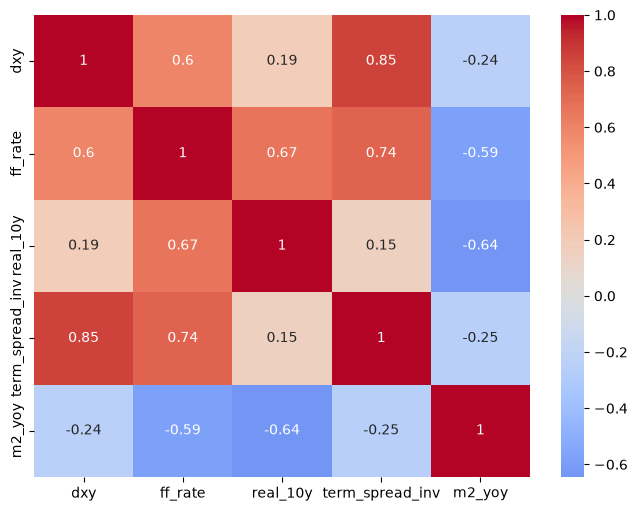

In [26]:
factor_matrix = model_df[
    factor_cols
].dropna()

corr_matrix = factor_matrix.corr()

display(corr_matrix)

plt.figure(figsize=(8,6))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    center=0
)

plt.show()

**実装内容**

- 5つの生ファクター列から欠損行を除き、ファクター間の相関行列 $C$ を計算する。

$$
C_{ij} = \mathrm{corr}(x_i, x_j)
$$

- 表と `seaborn.heatmap`(`coolwarm`, 中心 0, 数値注釈つき)で表示する。
- $|C_{ij}|$ が大きいペアは多重共線性の懸念があり、回帰係数の解釈が不安定になる。

#### 12. CSI v3試作

In [27]:
selected_factors = [
    "dxy_z",
    "ff_rate_z",
    "real_10y_z",
    "term_spread_inv_z",
    "m2_yoy_z"
]

model_df["CSI_v3_raw"] = (
    model_df[selected_factors]
    .mean(axis=1)
)

In [28]:
model_df["CSI_v3_smooth"] = (
    model_df["CSI_v3_raw"]
    .rolling(3)
    .mean()
)

**実装内容**

- 2つのセルで CSI v3 を作る。
  1. `CSI_v3_raw`: 5つの z-score の単純平均(`mean(axis=1)`)。

$$
\mathrm{CSI}^{raw}_t = \frac{1}{5}\bigl(z^{dxy}_t + z^{ff}_t + z^{real10y}_t + z^{ts\_inv}_t + z^{m2yoy}_t\bigr)
$$

  2. `CSI_v3_smooth`: 3か月移動平均で平滑化。

$$
\mathrm{CSI}^{smooth}_t = \frac{1}{3}\sum_{i=0}^{2}\mathrm{CSI}^{raw}_{t-i}
$$

- 各因子の重みは等しい。
- 緩和要因である `m2_yoy_z` も符号は反転せず足している点に注意する。v2 の `- m2_yoy_z` とは異なる。

#### 13. CSI v3検証

In [29]:
corr = (
    model_df[
        [
            "CSI_v3_smooth",
            "future_return"
        ]
    ]
    .dropna()
    .corr()
)

display(corr)

,CSI_v3_smooth,future_return
CSI_v3_smooth,1.000000,0.015888
future_return,0.015888,1.000000


In [30]:
fig = px.scatter(
    model_df,
    x="CSI_v3_smooth",
    y="future_return",
    trendline="ols",
    title="CSI_v3 vs Future Return"
)

fig.show()

**実装内容**(2つのコードセル)

1. `CSI_v3_smooth` と `future_return` の相関行列を、欠損除去後に表示する。

$$
\rho = \mathrm{corr}\bigl(\mathrm{CSI}^{smooth}_t,\ r_t\bigr)
$$

2. 両者の散布図を `px.scatter` で描き、`trendline="ols"` で最小二乗直線 $r = a + b\cdot\mathrm{CSI}$ を重ねる。傾き $b$ の符号が、CSI の上昇とリターンの関係を示す。

#### 14. Regime分析

In [31]:
model_df["regime"] = pd.qcut(
    model_df["CSI_v3_smooth"],
    q=4,
    labels=[
        "low",
        "mid_low",
        "mid_high",
        "high"
    ]
)

**実装内容**

- `CSI_v3_smooth` を `pd.qcut(q=4)` で四分位に分割し、`regime` 列を作る。
- ラベルは低い順に `low`, `mid_low`, `mid_high`, `high` である。
- 境界は分位点 $Q_{0.25}, Q_{0.5}, Q_{0.75}$ で、各レジームにほぼ同数の観測が入る。

$$
\mathrm{regime}_t = \begin{cases}
\text{low} & \mathrm{CSI}_t \le Q_{0.25} \\
\text{mid\_low} & Q_{0.25} < \mathrm{CSI}_t \le Q_{0.5} \\
\text{mid\_high} & Q_{0.5} < \mathrm{CSI}_t \le Q_{0.75} \\
\text{high} & \mathrm{CSI}_t > Q_{0.75}
\end{cases}
$$

- 分位点は全期間から決まる。`CSI_v3_smooth` が欠損の行は `NaN` になる。

#### 15. Regime別リターン評価

In [32]:
regime_return = (
    model_df
    .groupby("regime")
    ["future_return"]
    .agg(
        [
            "mean",
            "median",
            "std",
            "count"
        ]
    )
)

display(regime_return)

,mean,median,std,count
regime,,,,
low,0.019598,0.022019,0.027159,60
mid_low,0.007262,0.003329,0.076092,54
mid_high,0.009243,0.016558,0.037486,61
high,0.015266,0.013693,0.027663,57


**実装内容**

- `regime` ごとに `future_return` を `groupby` で集計し、平均、中央値、標準偏差、件数を表示する。

$$
\bar{r}_g = \frac{1}{n_g}\sum_{t\in g} r_t,\quad s_g = \sqrt{\frac{1}{n_g-1}\sum_{t\in g}(r_t-\bar{r}_g)^2}
$$

- `high` から `low` へ平均リターンが単調に変化するかを確認することで、CSI の水準別の効果を評価する。
- 件数 $n_g$ が小さいレジームは統計的に不安定である。

#### 16. 回帰分析

In [33]:
from sklearn.linear_model import LinearRegression

reg_df = model_df[
    selected_factors +
    ["future_return"]
].dropna()

X = reg_df[selected_factors]

y = reg_df["future_return"]

model = LinearRegression()

model.fit(X, y)

coef_df = pd.DataFrame(
    {
        "factor": selected_factors,
        "coef": model.coef_
    }
)

display(
    coef_df.sort_values(
        "coef",
        key=lambda s: s.abs(),
        ascending=False
    )
)

print("R² =", model.score(X, y))

,factor,coef
3,term_spread_inv_z,-0.017292
0,dxy_z,0.016545
2,real_10y_z,0.009955
4,m2_yoy_z,0.007097
1,ff_rate_z,-0.000096


R² = 0.07476063099962371


**実装内容**

- 5つの z-score を説明変数 $X$、`future_return` を目的変数 $y$ として、欠損行を除いたうえで `LinearRegression` を学習する。

$$
r_t = \beta_0 + \sum_{j=1}^{5}\beta_j z^{(j)}_t + \varepsilon_t
$$

- 最小二乗法で $\hat{\beta}=\arg\min\sum_t(r_t-\hat r_t)^2$ を求める。
- 係数 `coef_` を絶対値の降順で表示する。説明変数は標準化済みなので、係数の大きさを比較できる。
- 決定係数 `model.score(X, y)` を表示する。これは学習データ内の $R^2$ である。

$$
R^2 = 1 - \frac{\sum_t (r_t-\hat r_t)^2}{\sum_t (r_t-\bar r)^2}
$$

#### 17. 二値分類分析

In [34]:
model_df["crash"] = (
    model_df["future_return"] < -0.05
).astype(int)

display(
    model_df[
        [
            "crash",
            "CSI_v3_smooth"
        ]
    ]
    .groupby("crash")
    .mean()
)

,CSI_v3_smooth
crash,
0,-0.007696
1,-0.099460


**実装内容**

- 3か月先リターンが $-5\%$ を下回る月を急落(`crash=1`)とする二値ラベルを作る。

$$
\mathrm{crash}_t = \mathbf{1}\bigl[r_t < -0.05\bigr]
$$

- `crash` の値(0 / 1)ごとに `CSI_v3_smooth` の平均を比較する。
- `crash=1` の平均が `crash=0` より高ければ、CSI が高い局面で急落が起きやすいことを示唆する。
- `future_return` が `NaN` の行は比較が偽になり `crash=0` に入る。末尾3行が含まれる点に注意する。

#### 18. Walk Forward検証

In [35]:
from sklearn.model_selection import TimeSeriesSplit

tscv = TimeSeriesSplit(
    n_splits=5
)

scores = []

for train_idx, test_idx in tscv.split(reg_df):

    train = reg_df.iloc[train_idx]
    test = reg_df.iloc[test_idx]

    X_train = train[selected_factors]
    y_train = train["future_return"]

    X_test = test[selected_factors]
    y_test = test["future_return"]

    model = LinearRegression()

    model.fit(
        X_train,
        y_train
    )

    score = model.score(
        X_test,
        y_test
    )

    scores.append(score)

scores

[-31.194482455016328,
 -15.545104950349668,
 -3.973962638393906,
 -2.966601211008707,
 -0.612070580165339]

**実装内容**

- `TimeSeriesSplit(n_splits=5)` で時系列順の拡張窓分割を行う。学習期間は先頭から伸び、テスト期間は常にその直後になる。

$$
\text{split } s:\quad \text{train}=[1,\,t_s],\quad \text{test}=(t_s,\,t_{s+1}]
$$

- 各分割で `LinearRegression` を学習し、テスト期間の $R^2$ を `scores` に保存する。

$$
R^2_{s} = 1 - \frac{\sum_{t\in\text{test}}(r_t-\hat r_t)^2}{\sum_{t\in\text{test}}(r_t-\bar r_{\text{test}})^2}
$$

- $R^2_s<0$ は、テスト期間の平均値を使うより予測が悪いことを意味する。
- 将来データを学習に使わないため、回帰分析の学習内 $R^2$ より現実的な汎化性能の評価になる。

#### 19. Walk Forward結果可視化

In [36]:
wf_df = pd.DataFrame(
    {
        "split": range(
            1,
            len(scores)+1
        ),
        "r2": scores
    }
)

display(wf_df)

px.bar(
    wf_df,
    x="split",
    y="r2",
    title="Walk Forward R²"
).show()

,split,r2
0,1,-31.194482
1,2,-15.545105
2,3,-3.973963
3,4,-2.966601
4,5,-0.612071


**実装内容**

- `scores` に分割番号(1〜5)を付けて `wf_df`(`split`, `r2`)を作り、表示する。
- `px.bar` で分割ごとの $R^2$ を棒グラフにする。
- 棒が 0 を下回る分割は予測力がなく、分割間のばらつきからモデルの安定性を判断できる。

#### 20. V3最終評価

In [37]:
summary = {
    "single_factor_best":
        ranking_df.iloc[0]["factor"],

    "single_factor_corr":
        ranking_df.iloc[0]["best_corr"],

    "CSI_corr":
        model_df[
            [
                "CSI_v3_smooth",
                "future_return"
            ]
        ]
        .corr()
        .iloc[0,1],

    "avg_walkforward_r2":
        np.mean(scores)
}

summary

{'single_factor_best': 'm2_yoy',
 'single_factor_corr': np.float64(-0.22014622036673526),
 'CSI_corr': np.float64(0.015887677113771776),
 'avg_walkforward_r2': np.float64(-10.85844436698679)}

**実装内容**

これまでの結果を辞書 `summary` に集約する。

| キー | 内容 |
|---|---|
| `single_factor_best` | ランキング先頭のファクター名 |
| `single_factor_corr` | そのファクターの最良ラグ相関 $\rho_{k^*}$ |
| `CSI_corr` | $\mathrm{corr}(\mathrm{CSI}^{smooth}_t,\ r_t)$ |
| `avg_walkforward_r2` | $\overline{R^2}=\frac{1}{5}\sum_{s=1}^{5}R^2_s$ |

CSI 合成指標の相関が単独最良ファクターを上回るか、平均 Walk Forward $R^2$ が正かを比べることで、V3 の有効性を判断する。